## Experimento histórico

Este notebook conserva los cálculos y salidas previos a la revisión temporal. No usar sus métricas como conclusiones finales. El flujo vigente está en `ML.train`, `protocol.json` y `ML_Resultados_Finales.ipynb`. Las fechas y etiquetas se unifican en `features.py`.


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Cargar dataset
df = pd.read_csv("./Datasets/train.csv")

# Convertir fechas
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed"
)

# Crear copia para trabajar
df_clean = df.copy()

print("Registros:", len(df_clean))
print("Clientes:", df_clean["Customer ID"].nunique())
print("Pedidos:", df_clean["Order ID"].nunique())

Registros: 9800
Clientes: 793
Pedidos: 4922


In [4]:
rfm_features = df_clean.groupby('Customer ID').agg({
    'Order ID': 'nunique',
    'Sales': ['sum', 'mean', 'std'],
    'Category': 'nunique',
    'Sub-Category': 'nunique'
})

In [7]:
# ==========================
# 2. CREACIÓN DE RFM
# ==========================

fecha_observacion = df_clean["Order Date"].max()

rfm = (
    df_clean.groupby("Customer ID")
    .agg(
        Recency=(
            "Order Date",
            lambda x: (
                fecha_observacion - x.max()
            ).days
        ),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

# Definir churn
rfm["Churn"] = (
    rfm["Recency"] > 180
).astype(int)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Churn
0,AA-10315,184,5,5563.560,1
1,AA-10375,48,9,1056.390,0
2,AA-10480,259,4,1790.512,1
3,AA-10645,233,6,5086.935,1
4,AB-10015,445,3,886.156,1


In [8]:
# ==========================
# 3. VARIABLES DEL MODELO
# ==========================

rfm_features = (
    df_clean.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Monetary_Sum=("Sales", "sum"),
        Monetary_Mean=("Sales", "mean"),
        Monetary_Std=("Sales", "std"),
        Cat_Count=("Category", "nunique"),
        SubCat_Count=("Sub-Category", "nunique")
    )
    .reset_index()
)

rfm_features["Monetary_Std"] = (
    rfm_features["Monetary_Std"].fillna(0)
)

# Agregar Churn
rfm_features = rfm_features.merge(
    rfm[["Customer ID", "Churn"]],
    on="Customer ID",
    how="left"
)

rfm_features.head()

,Customer ID,Frequency,Monetary_Sum,Monetary_Mean,Monetary_Std,Cat_Count,SubCat_Count,Churn
0,AA-10315,5,5563.560,505.778182,1157.990034,3,9,1
1,AA-10375,9,1056.390,70.426000,126.508857,3,7,0
2,AA-10480,4,1790.512,149.209333,176.229194,3,7,1
3,AA-10645,6,5086.935,282.607500,429.222188,3,9,1
4,AB-10015,3,886.156,147.692667,139.432371,3,5,1


In [15]:
X = rfm_features.drop(
    columns=["Customer ID", "Churn"]
)

y = rfm_features["Churn"]

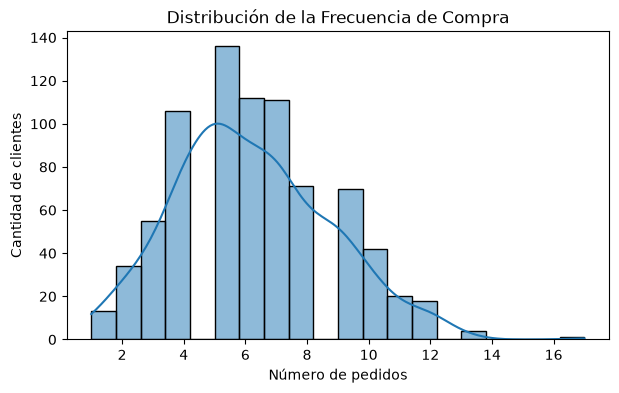

In [ ]:
# ==========================
# FRECUENCIA DE COMPRA
# ==========================

plt.figure(figsize=(7, 4))

sns.histplot(
    data=rfm_features,
    x="Frequency",
    bins=20,
    kde=True
)

plt.title("Distribución de la Frecuencia de Compra")
plt.xlabel("Número de pedidos")
plt.ylabel("Cantidad de clientes")

plt.show()

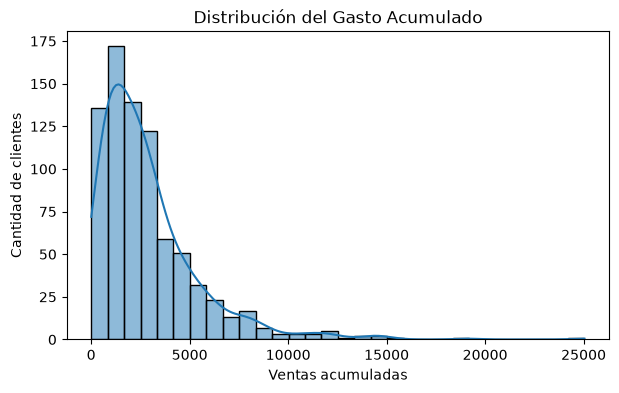

In [ ]:
# ==========================
# GASTO ACUMULADO
# ==========================

plt.figure(figsize=(7, 4))

sns.histplot(
    data=rfm_features,
    x="Monetary_Sum",
    bins=30,
    kde=True
)

plt.title("Distribución del Gasto Acumulado")
plt.xlabel("Ventas acumuladas")
plt.ylabel("Cantidad de clientes")

plt.show()

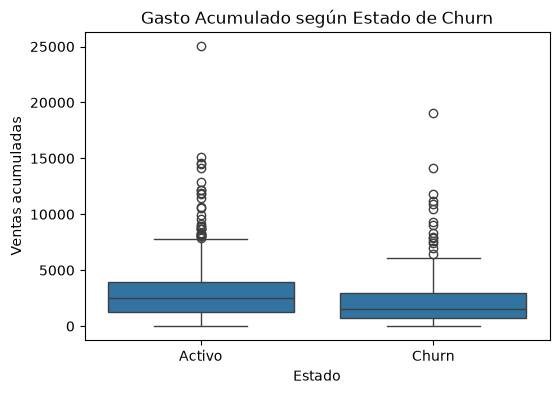

In [13]:
# ==========================
# GASTO SEGÚN CHURN
# ==========================

plt.figure(figsize=(6, 4))

sns.boxplot(
    data=rfm_features,
    x="Churn",
    y="Monetary_Sum"
)

plt.title("Gasto Acumulado según Estado de Churn")
plt.xlabel("Estado")
plt.ylabel("Ventas acumuladas")

plt.xticks(
    [0, 1],
    ["Activo", "Churn"]
)

plt.show()

In [17]:

# Variables independientes
X = rfm_features.drop(columns=["Customer ID", "Churn"])

# Variable objetivo
y = rfm_features["Churn"]

# División 80/20 con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True))

X_train: (634, 6)
X_test: (159, 6)
y_train: (634,)
y_test: (159,)

Distribución en entrenamiento:
Churn
0    0.697161
1    0.302839
Name: proportion, dtype: float64

Distribución en prueba:
Churn
0    0.698113
1    0.301887
Name: proportion, dtype: float64


In [19]:
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)
y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

print(X.columns)

Index(['Frequency', 'Monetary_Sum', 'Monetary_Mean', 'Monetary_Std',
       'Cat_Count', 'SubCat_Count'],
      dtype='str')


In [20]:
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)
y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

In [21]:

accuracy = accuracy_score(y_test, y_pred_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)
f1 = f1_score(y_test, y_pred_xgb)
roc_auc = roc_auc_score(y_test, y_proba_xgb)

print("=== MÉTRICAS XGBOOST ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_xgb))

=== MÉTRICAS XGBOOST ===
Accuracy:  0.7233
Precision: 0.5667
Recall:    0.3542
F1-Score:  0.4359
ROC-AUC:   0.6334

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.76      0.88      0.82       111
           1       0.57      0.35      0.44        48

    accuracy                           0.72       159
   macro avg       0.66      0.62      0.63       159
weighted avg       0.70      0.72      0.70       159



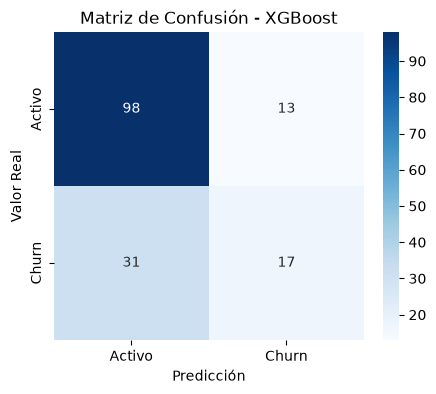

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - XGBoost")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

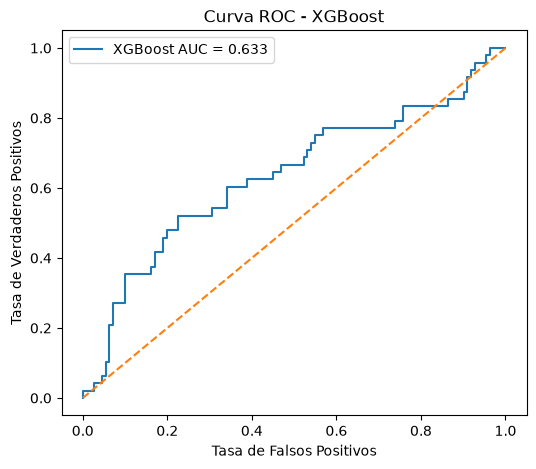

In [23]:

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_xgb
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Curva ROC - XGBoost")
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.legend()
plt.show()

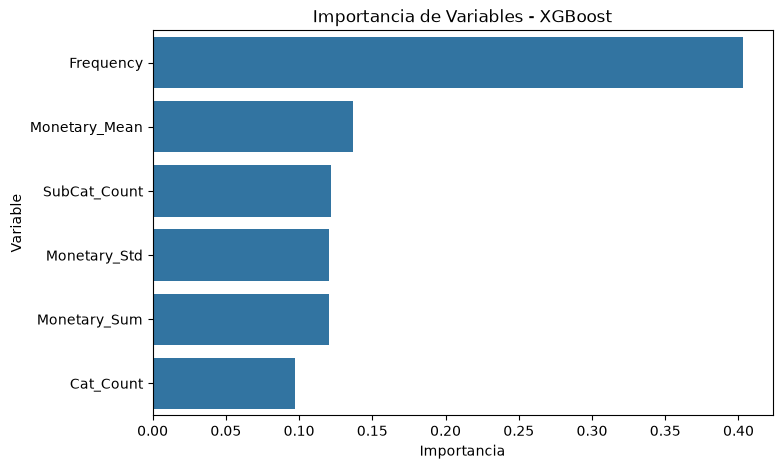

In [24]:
import pandas as pd

importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": model_xgb.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importancias,
    x="Importancia",
    y="Variable"
)

plt.title("Importancia de Variables - XGBoost")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.show()

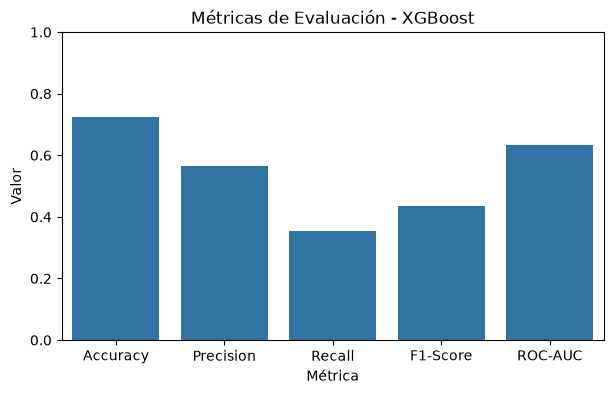

In [25]:
metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Valor": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

plt.figure(figsize=(7, 4))

sns.barplot(
    data=metricas,
    x="Métrica",
    y="Valor"
)

plt.ylim(0, 1)
plt.title("Métricas de Evaluación - XGBoost")
plt.ylabel("Valor")
plt.show()

In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train, y_train)

print("Mejores parámetros:")
print(grid_xgb.best_params_)

print("\nMejor Recall en validación cruzada:")
print(grid_xgb.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Mejores parámetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}

Mejor Recall en validación cruzada:
0.40607287449392715


In [27]:
best_xgb = grid_xgb.best_estimator_

y_pred_best = best_xgb.predict(X_test)
y_proba_best = best_xgb.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
roc_auc_best = roc_auc_score(y_test, y_proba_best)

print("=== XGBOOST OPTIMIZADO ===")
print(f"Accuracy:  {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1-Score:  {f1_best:.4f}")
print(f"ROC-AUC:   {roc_auc_best:.4f}")

=== XGBOOST OPTIMIZADO ===
Accuracy:  0.6981
Precision: 0.5000
Recall:    0.3542
F1-Score:  0.4146
ROC-AUC:   0.6410


In [28]:
comparacion = pd.DataFrame({
    "Modelo": [
        "XGBoost Base",
        "XGBoost Optimizado"
    ],
    "Accuracy": [
        accuracy,
        accuracy_best
    ],
    "Precision": [
        precision,
        precision_best
    ],
    "Recall": [
        recall,
        recall_best
    ],
    "F1-Score": [
        f1,
        f1_best
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_best
    ]
})

comparacion

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost Base,0.723270,0.566667,0.354167,0.435897,0.633446
1,XGBoost Optimizado,0.698113,0.500000,0.354167,0.414634,0.640953


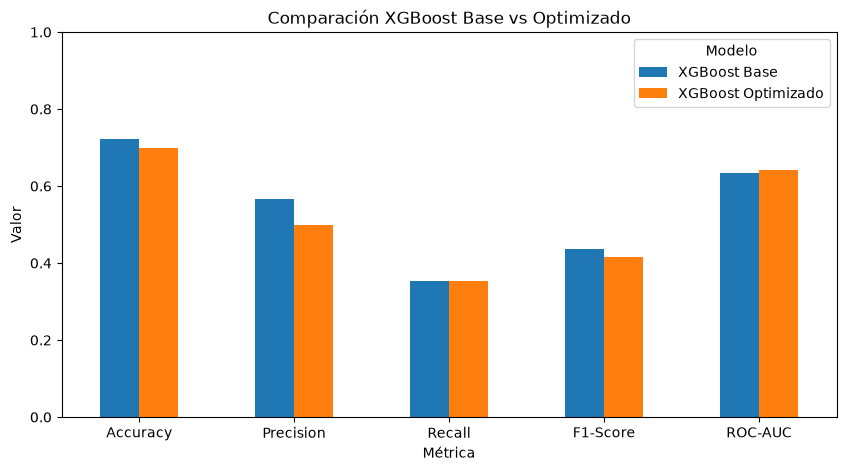

In [29]:
comparacion_plot = comparacion.set_index("Modelo").T

comparacion_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylim(0, 1)
plt.title("Comparación XGBoost Base vs Optimizado")
plt.ylabel("Valor")
plt.xlabel("Métrica")
plt.xticks(rotation=0)
plt.legend(title="Modelo")
plt.show()

In [31]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Antes de SMOTE:")
print(y_train.value_counts())

print("\nDespués de SMOTE:")
print(y_train_smote.value_counts())

Antes de SMOTE:
Churn
0    442
1    192
Name: count, dtype: int64

Después de SMOTE:
Churn
0    442
1    442
Name: count, dtype: int64


In [33]:
model_xgb_smote = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model_xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_smote = model_xgb_smote.predict(
    X_test
)

y_proba_smote = model_xgb_smote.predict_proba(
    X_test
)[:, 1]

accuracy_smote = accuracy_score(
    y_test,
    y_pred_smote
)

precision_smote = precision_score(
    y_test,
    y_pred_smote
)

recall_smote = recall_score(
    y_test,
    y_pred_smote
)

f1_smote = f1_score(
    y_test,
    y_pred_smote
)

roc_auc_smote = roc_auc_score(
    y_test,
    y_proba_smote
)

print("=== XGBOOST + SMOTE ===")
print(f"Accuracy:  {accuracy_smote:.4f}")
print(f"Precision: {precision_smote:.4f}")
print(f"Recall:    {recall_smote:.4f}")
print(f"F1-Score:  {f1_smote:.4f}")
print(f"ROC-AUC:   {roc_auc_smote:.4f}")

print("\nReporte:")
print(
    classification_report(
        y_test,
        y_pred_smote
    )
)

=== XGBOOST + SMOTE ===
Accuracy:  0.6918
Precision: 0.4912
Recall:    0.5833
F1-Score:  0.5333
ROC-AUC:   0.6776

Reporte:
              precision    recall  f1-score   support

           0       0.80      0.74      0.77       111
           1       0.49      0.58      0.53        48

    accuracy                           0.69       159
   macro avg       0.65      0.66      0.65       159
weighted avg       0.71      0.69      0.70       159



X_train: (634, 6)
X_test: (159, 6)

Antes de SMOTE:
Churn
0    442
1    192
Name: count, dtype: int64

Después de SMOTE:
Churn
0    442
1    442
Name: count, dtype: int64


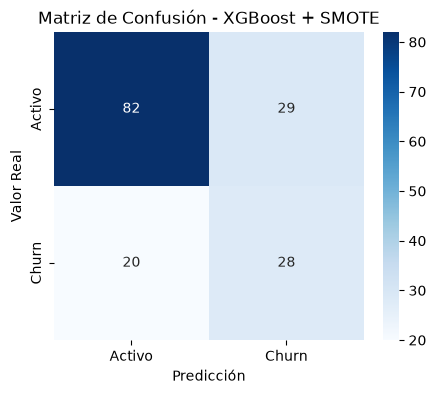

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# ==========================
# 1. CARGAR DATOS
# ==========================

df = pd.read_csv("./Datasets/train.csv")

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed"
)

# ==========================
# 2. CREAR CHURN
# ==========================

fecha_observacion = df["Order Date"].max()

rfm = (
    df.groupby("Customer ID")
    .agg(
        Recency=(
            "Order Date",
            lambda x: (
                fecha_observacion - x.max()
            ).days
        ),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm["Churn"] = (
    rfm["Recency"] > 180
).astype(int)

# ==========================
# 3. VARIABLES DEL MODELO
# ==========================

rfm_features = (
    df.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Monetary_Sum=("Sales", "sum"),
        Monetary_Mean=("Sales", "mean"),
        Monetary_Std=("Sales", "std"),
        Cat_Count=("Category", "nunique"),
        SubCat_Count=("Sub-Category", "nunique")
    )
    .reset_index()
)

rfm_features["Monetary_Std"] = (
    rfm_features["Monetary_Std"].fillna(0)
)

rfm_features = rfm_features.merge(
    rfm[["Customer ID", "Churn"]],
    on="Customer ID",
    how="left"
)

# ==========================
# 4. TRAIN / TEST
# ==========================

X = rfm_features.drop(
    columns=["Customer ID", "Churn"]
)

y = rfm_features["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# ==========================
# 5. SMOTE
# ==========================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAntes de SMOTE:")
print(y_train.value_counts())

print("\nDespués de SMOTE:")
print(y_train_smote.value_counts())

# ==========================
# 6. XGBOOST + SMOTE
# ==========================

model_xgb_smote = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model_xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_xgb_smote = model_xgb_smote.predict(
    X_test
)

# ==========================
# 7. MATRIZ DE CONFUSIÓN
# ==========================

cm_xgb_smote = confusion_matrix(
    y_test,
    y_pred_xgb_smote
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_xgb_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - XGBoost + SMOTE")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")

plt.show()

In [34]:
comparacion_final = pd.DataFrame({
    "Modelo": [
        "XGBoost Base",
        "XGBoost Optimizado",
        "XGBoost + SMOTE"
    ],
    "Accuracy": [
        accuracy,
        accuracy_best,
        accuracy_smote
    ],
    "Precision": [
        precision,
        precision_best,
        precision_smote
    ],
    "Recall": [
        recall,
        recall_best,
        recall_smote
    ],
    "F1-Score": [
        f1,
        f1_best,
        f1_smote
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_best,
        roc_auc_smote
    ]
})

comparacion_final

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost Base,0.723270,0.566667,0.354167,0.435897,0.633446
1,XGBoost Optimizado,0.698113,0.500000,0.354167,0.414634,0.640953
2,XGBoost + SMOTE,0.691824,0.491228,0.583333,0.533333,0.677553


In [35]:
import joblib

joblib.dump(
    model_xgb_smote,
    "modelo_xgboost_smote.pkl"
)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.
